# CS5494 Assignment 1 — Tasks 1.1 and 1.2

**Members:** 林扬骐 (60815456), 许鸿彬 (60857945), 窦志勇 (60412495).

**Scope:** Task 1.1 (FVSBN) and Task 1.2 (neural autoregressive generation).
Task 1.3 (GAN) remains to be completed before the whole assignment is submitted.

We learn probability distributions over binarized MNIST and generate new images
without providing a digit label or a reference image. Both models use the exact
autoregressive factorization, but differ in the expressiveness of their conditional
probabilities. FVSBN is a logistic-regression baseline; MADE uses masked hidden
layers. We compare their likelihood, visual samples, capacity, training-data
requirements, and measured training/inference cost.

**How to read/run:** Run All with the `cs5494` Python environment. The default
loads saved checkpoints and validates their likelihoods. Training is available
through `python run_task12.py --repeat-seeds`. Source code is in
`autoregressive.py` and `run_task12.py`; setup instructions are in `READ.ME`.


In [1]:
from pathlib import Path
import json
import numpy as np
import torch
from IPython.display import display, Image, Markdown
from autoregressive import FVSBN, MADE, check_causality
from run_task12 import load_checkpoint, load_data, evaluate, ensure_artifacts
import run_task12

ensure_artifacts()  # First run restores the bundled data and results.
ROOT = run_task12.ROOT
RESULTS = ROOT / 'results/task12'
run_task12.OUT = RESULTS
assert (RESULTS / "comparison.json").exists(), "Run python run_task12.py --repeat-seeds first."
torch.set_num_threads(4)
selection = json.loads((RESULTS / "selection.json").read_text(encoding="utf-8"))
print("Selected checkpoints:", selection)
print("Current verification environment:", torch.__version__, "CPU")


Selected checkpoints: {'task1': 'fvsbn', 'task2': 'made_512x2_skip', 'rule': 'lowest validation NLL among full-data seed-0 MADE configurations', 'test_used_for_selection': False}
Current verification environment: 2.14.0+cpu CPU


## Data preprocessing and experimental protocol

The original MNIST training set is randomly split into **55,000 training** and
**5,000 validation** images, using split seed 5494. The official **10,000 test**
images remain held out. Exact split indices and input-file SHA-256 fingerprints
are saved. No digit labels are used for training these generative models.

Each uint8 pixel is mapped to 1 if it is at least 128 and to 0 otherwise
(equivalent to normalized intensity > 0.5). Each 28×28 image is flattened to
784 pixels in row-major raster order. This is thresholded MNIST, **not** the
predefined stochastic-binarized MNIST benchmark; its NLL should not be directly
compared with numbers from a differently preprocessed dataset.

All primary capacity comparisons use 40 epochs, batch size 256, Adam with initial
learning rate 0.001 and cosine decay to 0.0001, no weight decay, and gradient
norm clipping at 10. Output biases start from training-only empirical pixel
log-odds. Each checkpoint is chosen by validation NLL. The main MADE architecture
is selected by validation NLL among the full-data seed-0 configurations;
test scores do not select the model. Its repeated seeds change initialization
and minibatch order while keeping the split and masks fixed.

The 10k-data ablation uses the first 10,000 indices of the same shuffled training
partition. Validation and test sets remain unchanged. It uses the same number of
epochs, so it also has fewer optimizer updates; it does not isolate data volume
under an equal-update compute budget.

The independent Bernoulli baseline estimates one probability per pixel from the
55,000 training images, clamps probabilities to [0.0001, 0.9999], and evaluates
on the same 10,000 test images as the learned models.


## Task 1.1 — Fully Visible Sigmoid Belief Network

For a binary image $x\in\{0,1\}^{784}$, the chain rule gives

$$p_\theta(x)=\prod_{j=1}^{784}p_\theta(x_j\mid x_{<j}).$$

The FVSBN parameterizes each conditional with logistic regression:

$$\ell_j=b_j+\sum_{i<j}W_{ji}x_i,\qquad
p_\theta(x_j=1\mid x_{<j})=\sigma(\ell_j).$$

A strict lower-triangular mask removes the diagonal and all future connections.
There are no hidden or latent variables. Binary cross-entropy with logits is
summed over pixels to compute the exact negative log-likelihood per image,
then averaged over the minibatch for optimization:

$$\mathcal{L}=\frac{1}{B}\sum_{n=1}^{B}\sum_{j=1}^{784}
\left[\operatorname{softplus}(\ell_j^{(n)})-x_j^{(n)}\ell_j^{(n)}\right].$$

Training evaluates all conditionals in one masked matrix multiplication.
Generation uses 784 sequential Bernoulli draws. The optimized sampler computes
only the requested weight row at each step; it avoids recalculating all 784
outputs. Its samples are tested against the generic ancestral sampler.

The implementation allocates a dense matrix for efficient operations but only
307,720 coefficients (including biases) are active. Reporting all 615,440
allocated parameters as effective trainable connections would overstate capacity.


Selected epoch: 40
Parameter counts: {'allocated': 615440, 'active': 307720}
Causality check: {'max_logit_change': 0.0, 'pivots_checked': 21}


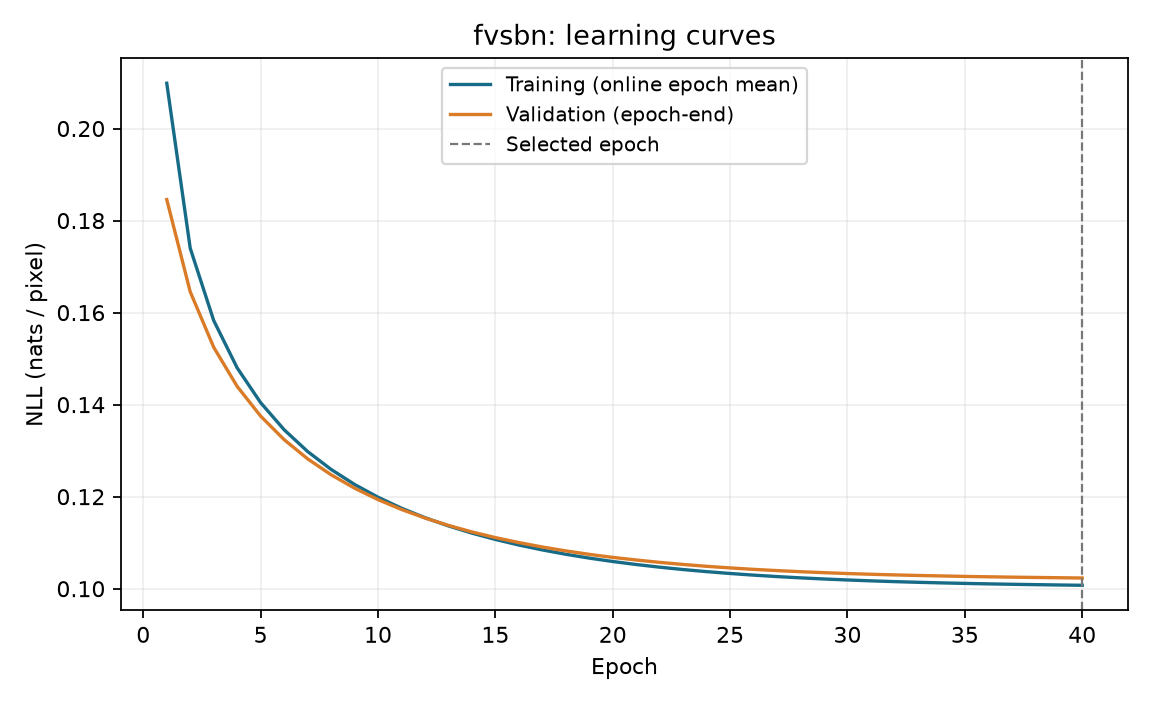

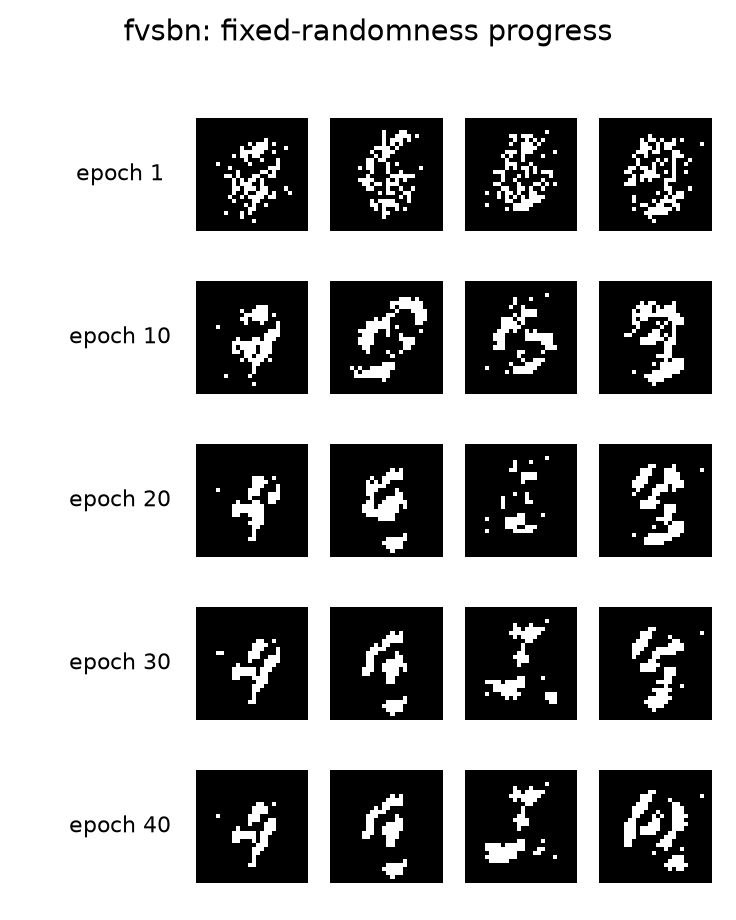

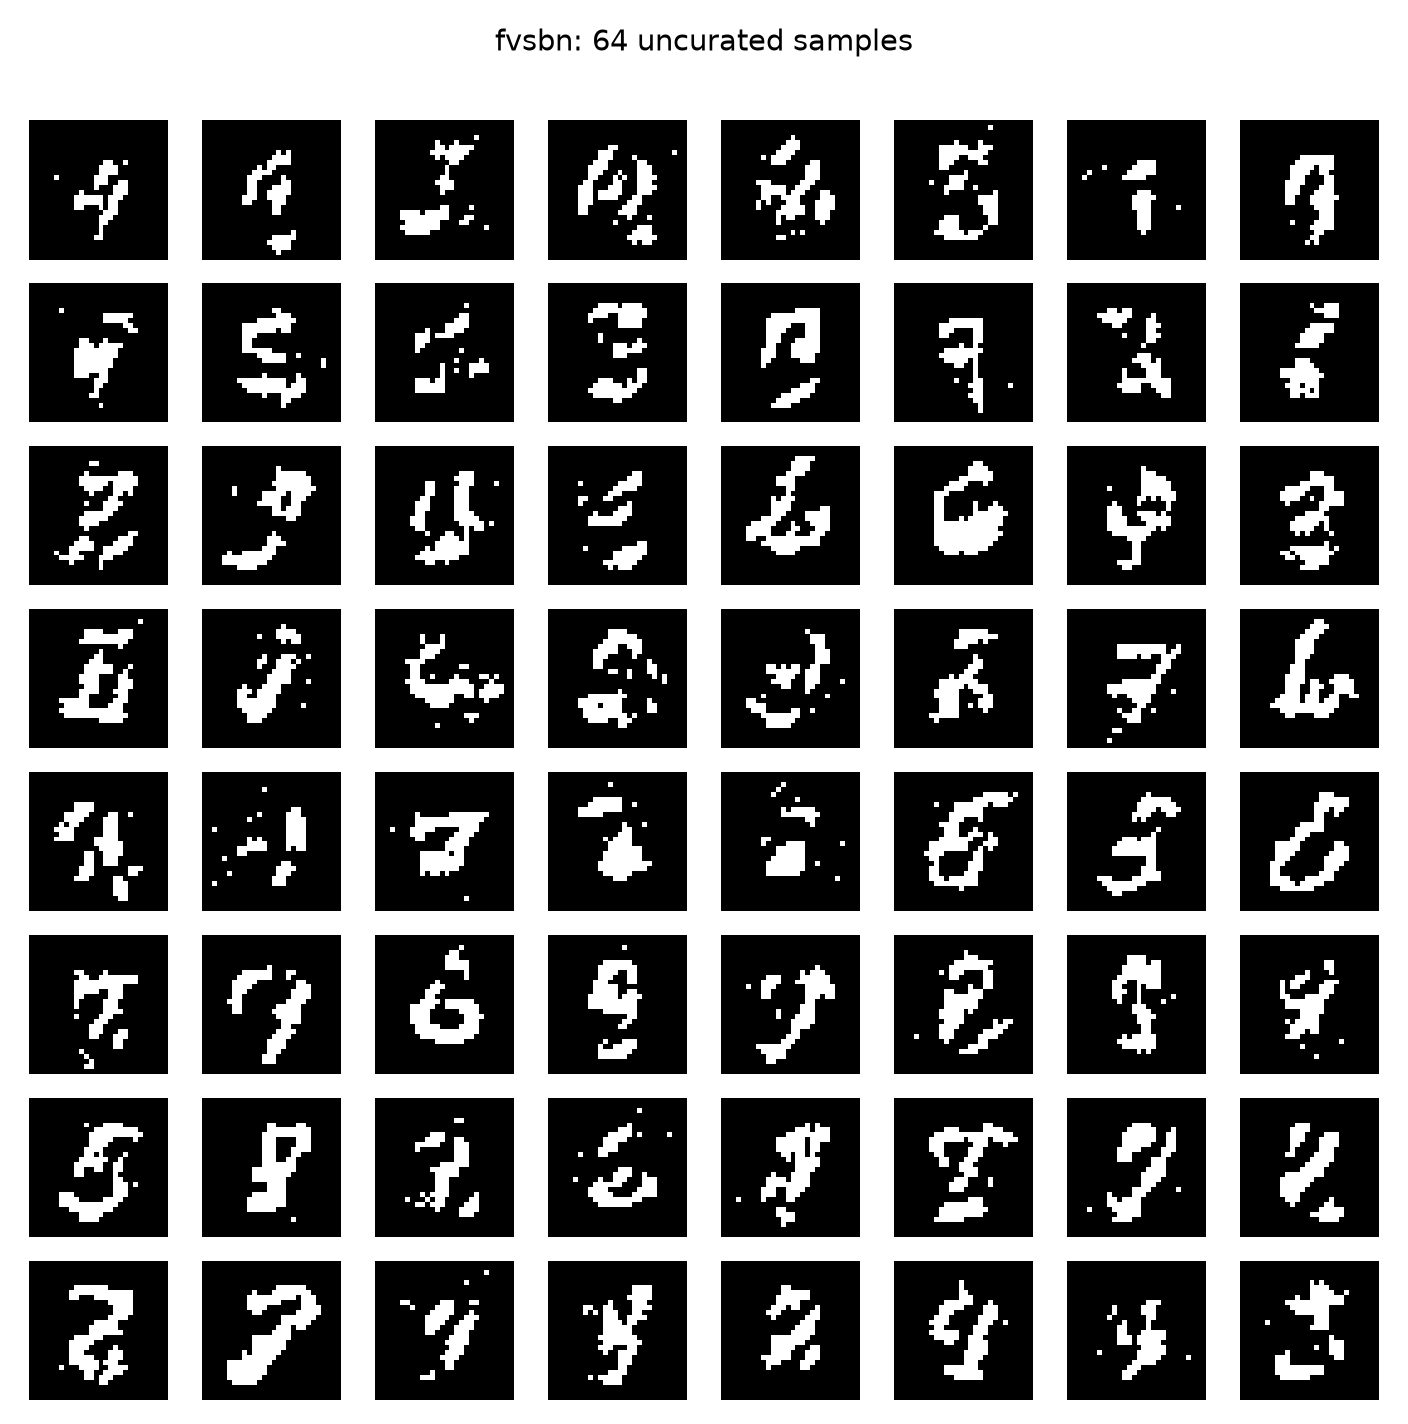

In [2]:
model_fvsbn, checkpoint_fvsbn = load_checkpoint(RESULTS / selection['task1'] / "best.pt")
print("Selected epoch:", checkpoint_fvsbn["epoch"])
print("Parameter counts:", model_fvsbn.parameter_counts())
print("Causality check:", check_causality(model_fvsbn))
for filename in ["loss_curve.png", "progress.png", "samples.png"]:
    display(Image(filename=str(RESULTS / selection['task1'] / filename)))


## Task 1.2 — Neural autoregressive model (MADE)

We use **MADE**, a masked feed-forward network, following Germain et al. (2015).
The ordering and Bernoulli likelihood are the same as for FVSBN. Input/output
pixel $j$ has degree $j\in\{1,\ldots,784\}$. Hidden degrees span 1 through 783.
An input/hidden connection is retained when
$m_{\mathrm{previous}}\le m_{\mathrm{next}}$; the final hidden-to-output
connection requires $m_{\mathrm{hidden}}<j$.

$$h^{(l)}=\operatorname{ReLU}((W^{(l)}\odot M^{(l)})h^{(l-1)}+b^{(l)}),$$
$$\ell=(W^{(out)}\odot M^{(out)})h^{(L)}+b^{(out)}.$$

Any path into output $j$ therefore starts at a pixel strictly before $j$.
All conditional logits and the exact likelihood are obtained in **one forward
pass during training and evaluation**. Only generation is sequential. The old
draft's 784 separate training forward passes were unnecessary for this masked
MLP. This implementation is named MADE rather than classic NADE to match its
actual architecture.

We test width (256 vs. 512), depth (one vs. two layers), and a clearly identified
variant that adds a strict lower-triangular input-to-output linear connection:
$\ell_{skip}=\ell_{MLP}+(A\odot M_{strict})x$. This connection preserves
causality and lets the nonlinear network augment the linear conditional model.

The capacity variants use the same optimizer schedule, split, pixel order,
and training seed. Their parameter counts differ. A separate 10k experiment
tests data availability. These comparisons are useful controlled experiments,
but do not constitute an exhaustive hyperparameter search.


Selected epoch: 40
Parameter counts: {'allocated': 1681424, 'active': 841480}
Causality check: {'max_logit_change': 0.0, 'pivots_checked': 21}


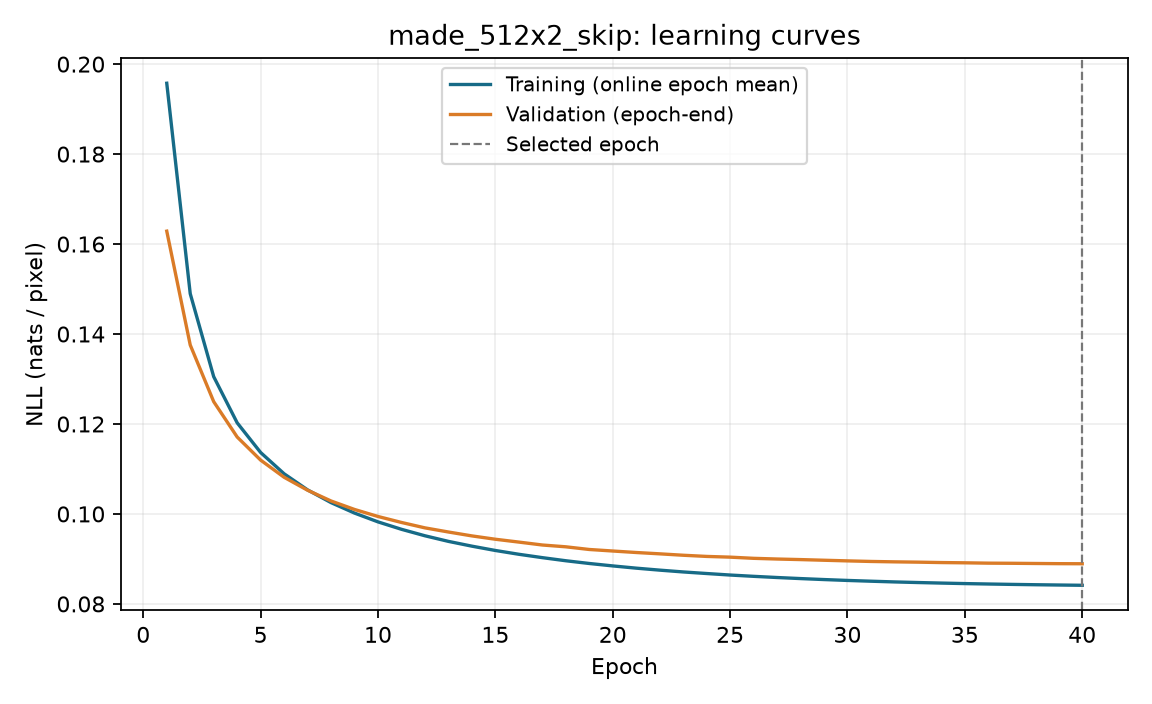

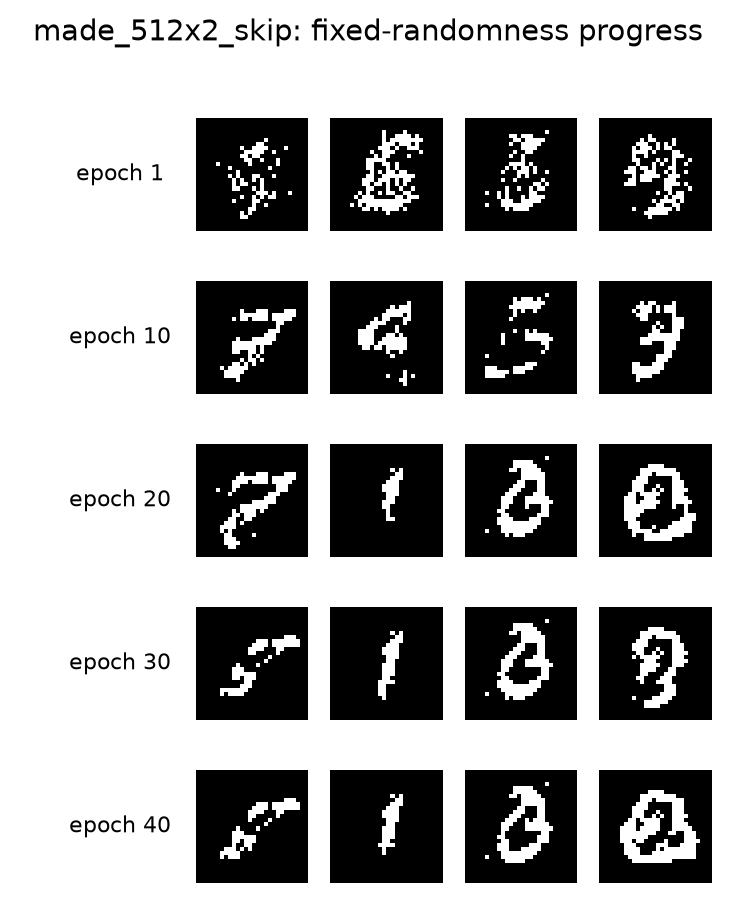

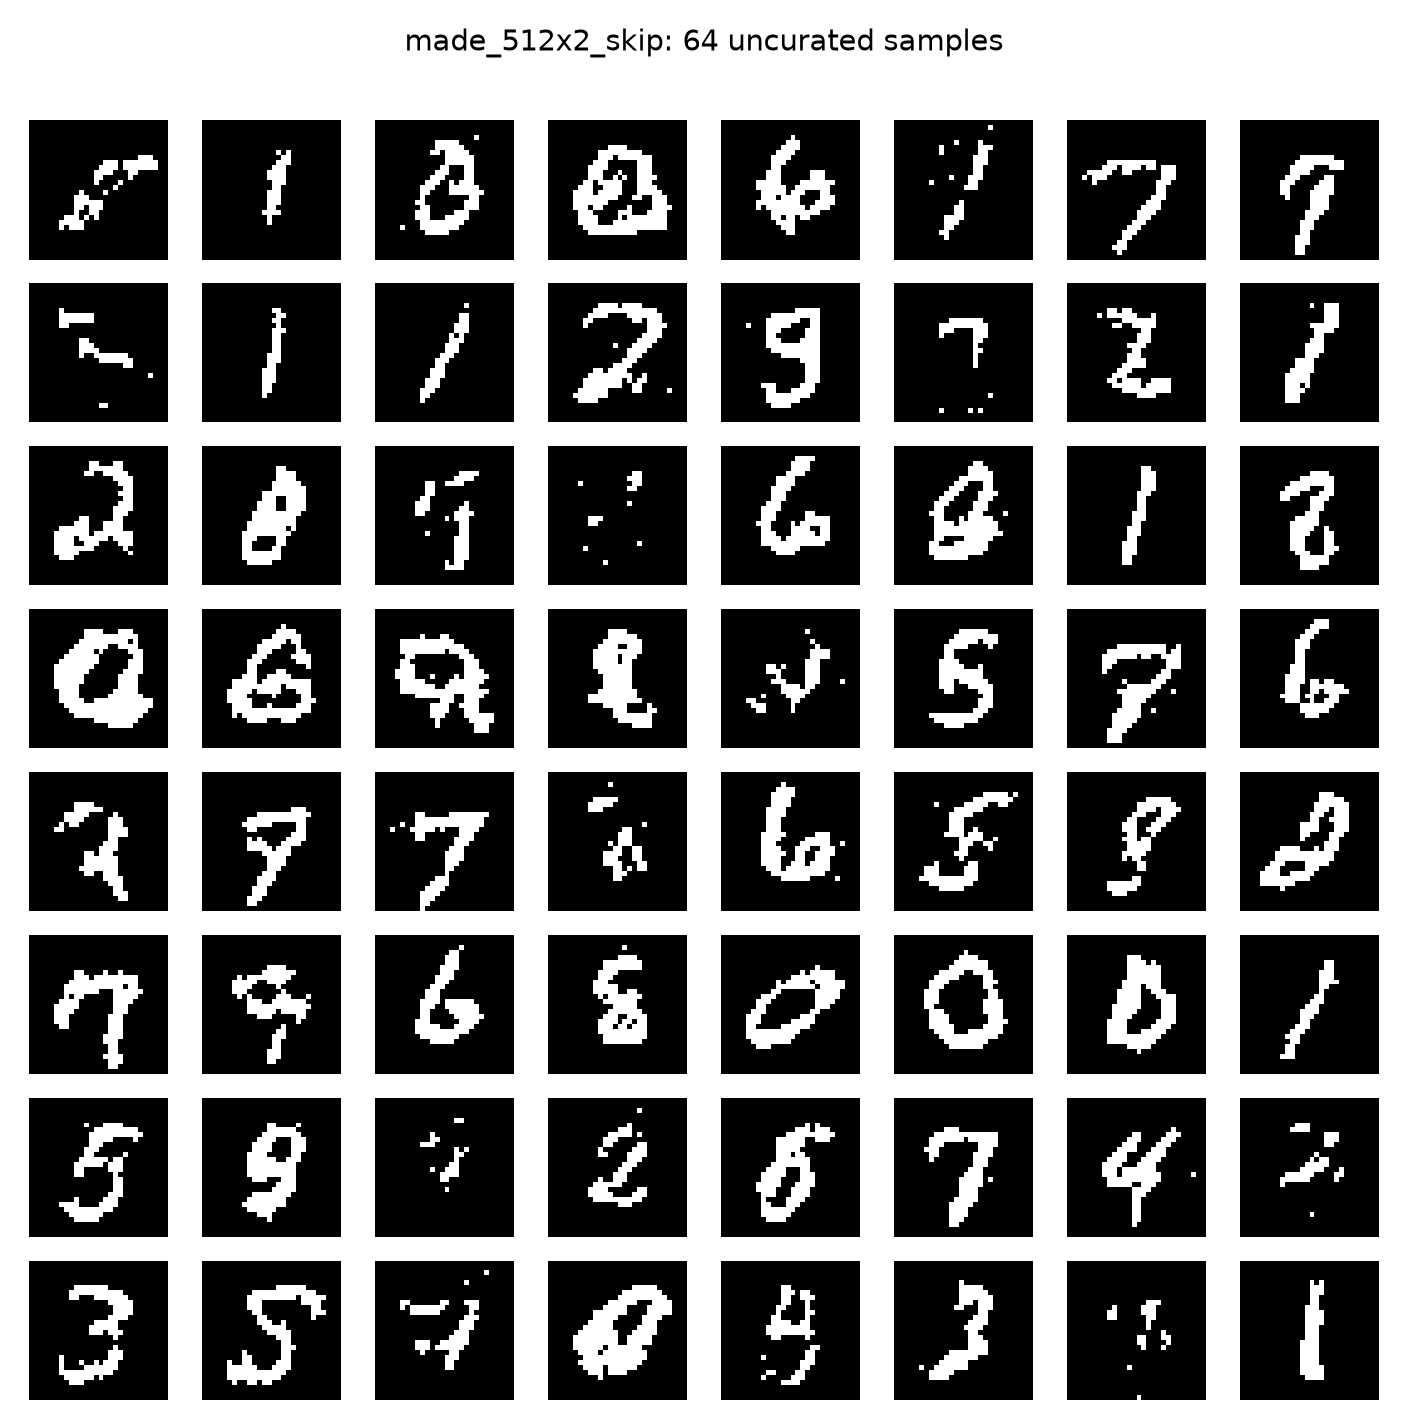

In [3]:
model_made, checkpoint_made = load_checkpoint(RESULTS / selection['task2'] / "best.pt")
print("Selected epoch:", checkpoint_made["epoch"])
print("Parameter counts:", model_made.parameter_counts())
print("Causality check:", check_causality(model_made))
for filename in ["loss_curve.png", "progress.png", "samples.png"]:
    display(Image(filename=str(RESULTS / selection['task2'] / filename)))


## Evaluation and verification

- Exact held-out NLL is reported in **nats/image**, **nats/pixel** (divide by
  784), and **bits/pixel** (divide by $784\log 2$). Lower is better.
- Each final model displays the first 64 samples from seed 2026, without
  filtering. A separate 10-image grid satisfies the recommended sample count.
- Progress grids use the same uniform random numbers across epochs. Each row
  is one checkpoint stage, making changes easier to compare. The progress grid
  describes the training trajectory; final samples use the best validation checkpoint.
- Learning curves distinguish the training loss averaged during parameter
  updates from the validation loss evaluated at epoch end. Final train NLL in
  the table is recomputed at the selected checkpoint.
- Training wall time includes optimization, validation, checkpoint writes,
  and progress sampling; optimizer-loop time is also saved separately.
  Inference is measured after warm-up, with the median of three 10-image draws.
  All reported times are from this CPU environment, not the original draft's machine.
- Mathematical tests enumerate a small binary distribution to verify total
  probability 1, check the full small-model Jacobian for self/future leakage,
  compare vectorized and prefix-conditioned logits, and check sampler equivalence
  and reproducibility. Full-size trained models also undergo perturbation checks.
- Test-image confidence intervals measure uncertainty over test examples only.
  Repeated training seeds separately assess initialization/minibatch sensitivity.


## Measured results

All likelihoods in the validation/test columns are **nats per image**.
The independent-pixel baseline reaches **205.856 nats/image**
(0.26257 nats/pixel) on the same held-out test set.

| Model | Train n | Best epoch | Active parameters | Validation NLL | Test NLL | nats/pixel | Train wall (s) | 10 samples (s) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| fvsbn | 55000 | 40 | 307,720 | 80.224 | 79.380 | 0.10125 | 33.46 | 0.0146 |
| made_256 | 55000 | 40 | 201,744 | 92.068 | 90.935 | 0.11599 | 31.15 | 0.0632 |
| made_512 | 55000 | 40 | 402,704 | 80.560 | 79.642 | 0.10158 | 51.02 | 0.1031 |
| made_512x2 | 55000 | 40 | 534,544 | 84.069 | 83.280 | 0.10622 | 76.19 | 0.1519 |
| made_512x2_skip | 55000 | 40 | 841,480 | 69.719 | 69.122 | 0.08817 | 108.28 | 0.2460 |
| made_512x2_10k | 10000 | 40 | 534,544 | 106.637 | 105.640 | 0.13474 | 19.31 | 0.1324 |
| made_512x2_skip_seed1 | 55000 | 40 | 841,480 | 69.643 | 69.153 | 0.08820 | 106.71 | 0.2409 |
| made_512x2_skip_seed2 | 55000 | 40 | 841,480 | 69.653 | 69.099 | 0.08814 | 108.61 | 0.2577 |

The validation-selected task 1.2 model is **made_512x2_skip**.
Its test NLL is **10.258 nats/image lower** than FVSBN.
For MADE minus FVSBN, the paired test-image difference is -10.258,
with approximate 95% interval [-10.386, -10.130].
This interval concerns test examples, not the uncertainty of training a new model.

Across 3 training seeds, the selected architecture has test NLL 69.125 ± 0.027 nats/image (mean ± sample standard deviation). These repeats keep the data split and masks fixed.

Measured training wall times sum to **534.7 seconds (8.91 minutes)**
across all table rows. Final evaluation, final sample export, and report assembly
are additional. Environment: Windows-11-10.0.26200-SP0, CPU, 4 threads,
PyTorch 2.14.0+cpu, NumPy 2.5.2.


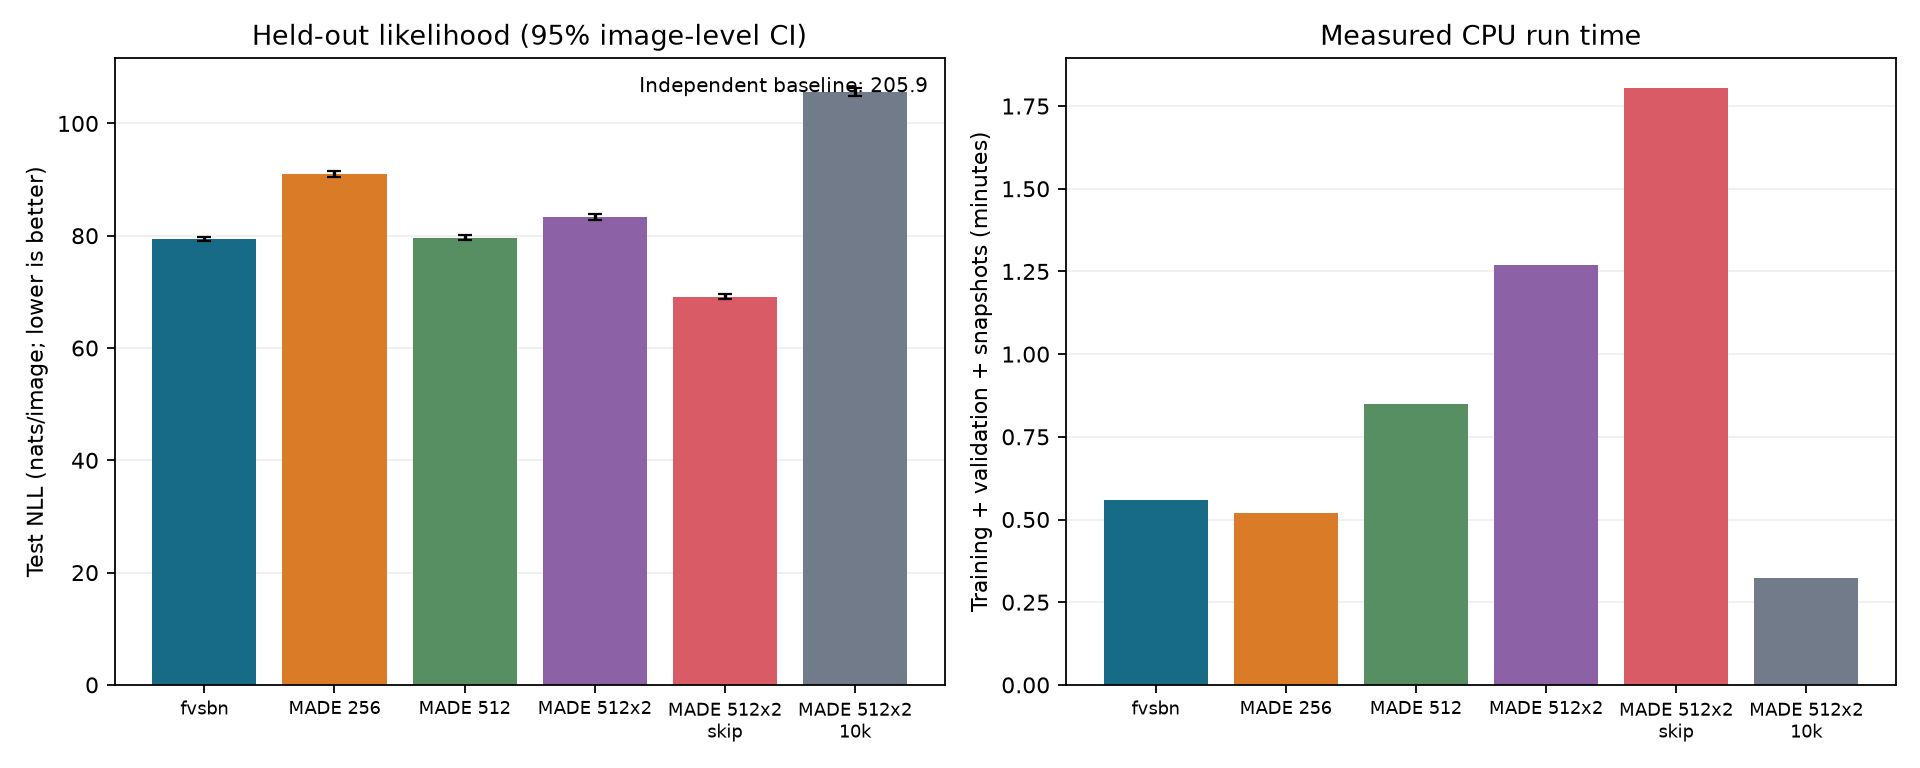

In [4]:
display(Image(filename=str(RESULTS / "comparison.png")))

In [5]:
# Recompute exact likelihood for both selected checkpoints on all 10,000 test images.
# Only loading/evaluation is performed here; no optimizer is run.
train_data, validation_data, test_data, data_info = load_data()
print("Data sizes:", len(train_data), len(validation_data), len(test_data))
for key, model in [("task1", model_fvsbn), ("task2", model_made)]:
    recorded = json.loads((RESULTS / selection[key] / "metrics.json").read_text(encoding="utf-8"))
    assert recorded["data_fingerprint"] == data_info["fingerprint"]
    actual, _ = evaluate(model, test_data)
    assert abs(actual["nll_image"] - recorded["test"]["nll_image"]) < 1e-3
    samples = model.sample(10, seed=2026)
    assert samples.shape == (10, 784) and ((samples == 0) | (samples == 1)).all()
    saved = np.load(RESULTS / selection[key] / "samples.npy")
    assert np.array_equal(samples.numpy(), saved[:10])
    print(selection[key], "verified:", actual)


Data sizes: 55000 5000 10000
fvsbn verified: {'nll_image': 79.37979888916016, 'nll_pixel': 0.10124974697828293, 'bits_pixel': 0.1460725028114217, 'standard_error_image': 0.2002996826171875, 'n': 10000}


made_512x2_skip verified: {'nll_image': 69.12167358398438, 'nll_pixel': 0.08816540241241455, 'bits_pixel': 0.1271957853285203, 'standard_error_image': 0.2134011459350586, 'n': 10000}


## Interpretation of the controlled comparisons

Negative differences below mean lower (better) held-out NLL for the first configuration.

- **Width:** MADE-512 minus MADE-256 = -11.293 nats/image.
- **Depth:** MADE-512×2 minus MADE-512 = +3.638 nats/image.
- **Linear skip:** MADE-512×2 with skip minus without skip = -14.158 nats/image.
- **Data:** MADE-512×2 trained on 10k minus 55k = +22.360 nats/image.

In this run, increasing width improves likelihood, while adding a second layer
without a direct linear connection does not. The skip variant substantially
improves the two-layer model. A plausible explanation is that it can retain
simple pixel dependencies while hidden layers model nonlinear corrections;
this experiment does not separately identify optimization and representation
effects. The smaller-data condition performs worse, with the update-budget
confound noted above. Thus model complexity alone is not a reliable predictor
of performance under a fixed training schedule.

These are observed comparisons under a common 40-epoch schedule, not universal
claims that wider/deeper networks always perform better. Changes in parameter
count and optimization difficulty should be considered. The 10k condition has
fewer updates as well as fewer distinct examples. The selected checkpoint's
train/test gaps are 0.444 nats/image for
FVSBN and 3.276 for the selected MADE.
These gaps alone do not establish the absence of overfitting; the validation
curves and checkpoint selection provide complementary evidence.

Both models model dependencies beyond independent pixels. FVSBN is a useful
efficient baseline. MADE adds nonlinear capacity, but sequential generation
still requires 784 conditional decisions. Its generic sampler recomputes the
masked network at each step, whereas the FVSBN sampler exploits its linear form.
The measured inference comparison therefore includes both model and implementation costs.


## Generated samples and nearest training images

We search all 55,000 training images for the nearest binary image to each of the
64 uncurated generated samples, using Hamming distance (number of differing pixels).
FVSBN has 0 exact training matches among these
64 samples, with mean nearest distance 57.59 pixels.
The selected MADE has 0 exact matches, with
mean nearest distance 43.77 pixels.
The figures display the first eight pairs without manual selection.

These checks help inspect possible copying, but no exact match does **not** prove
absence of memorization. A smaller nearest distance is also not automatically
better generative quality. Recognizability, diversity, and held-out likelihood
remain separate considerations.

Visual inspection of the supplied seed-2026 grids shows more fragmented strokes
and ambiguous shapes in FVSBN. The selected MADE produces many clearer digit-like
shapes, including thin vertical strokes and closed loops, while some images are
still broken or difficult to recognize. The results demonstrate generation
capability but do not establish perfect digit quality or balanced digit classes.


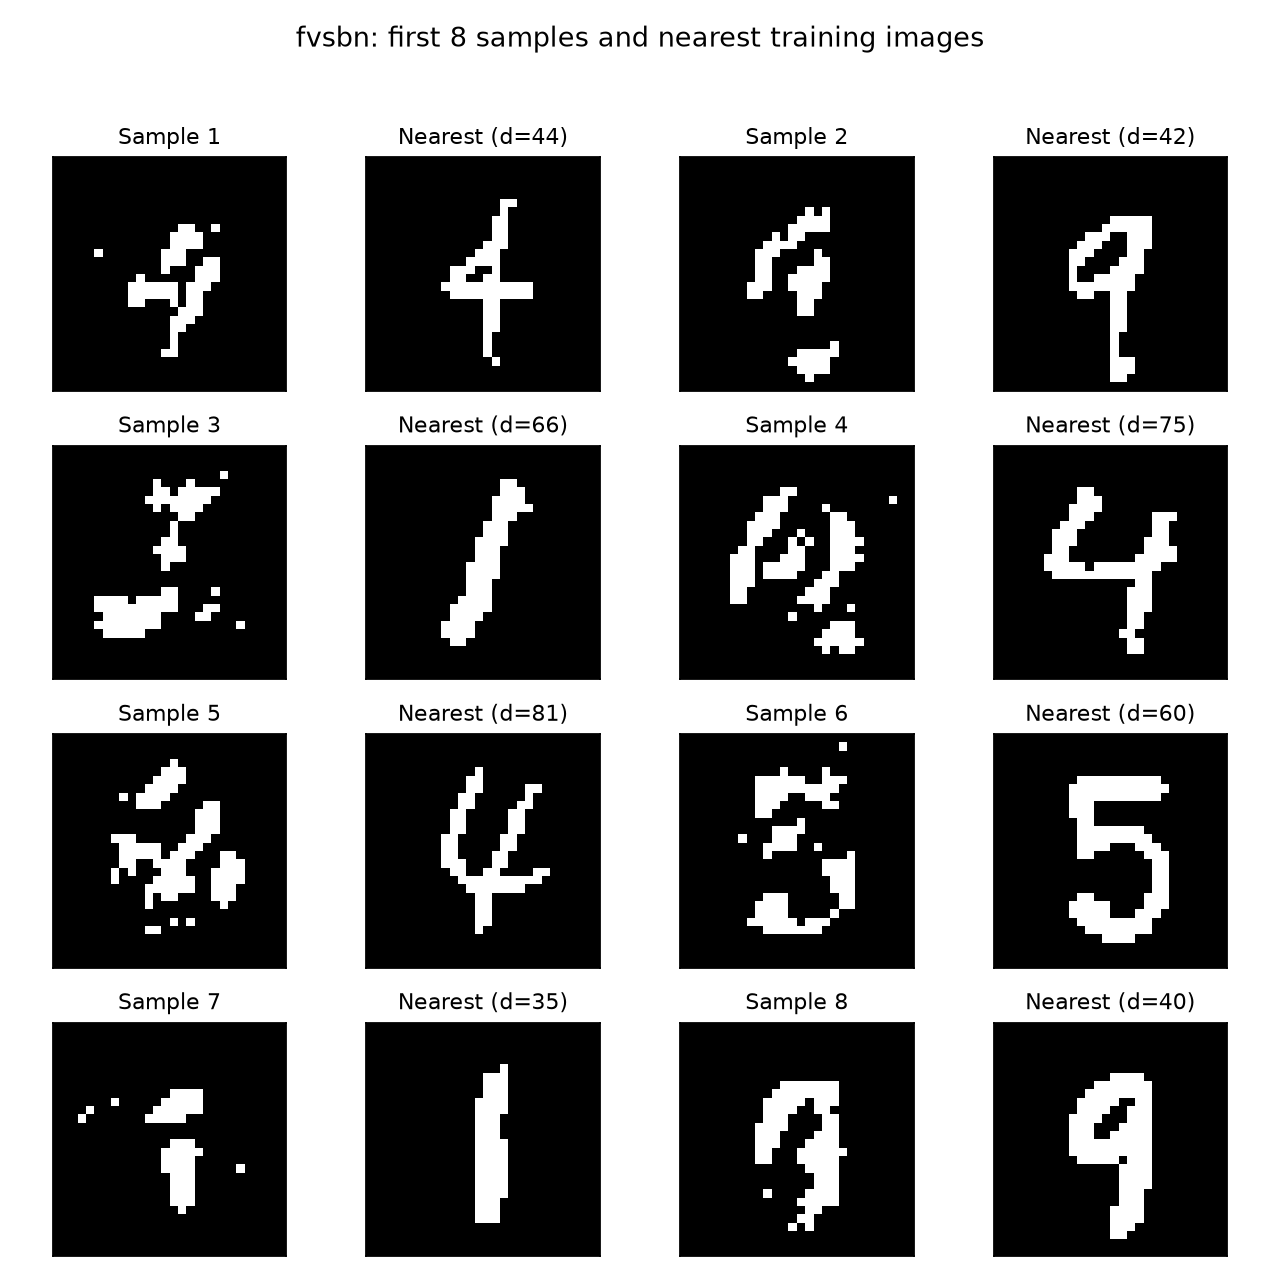

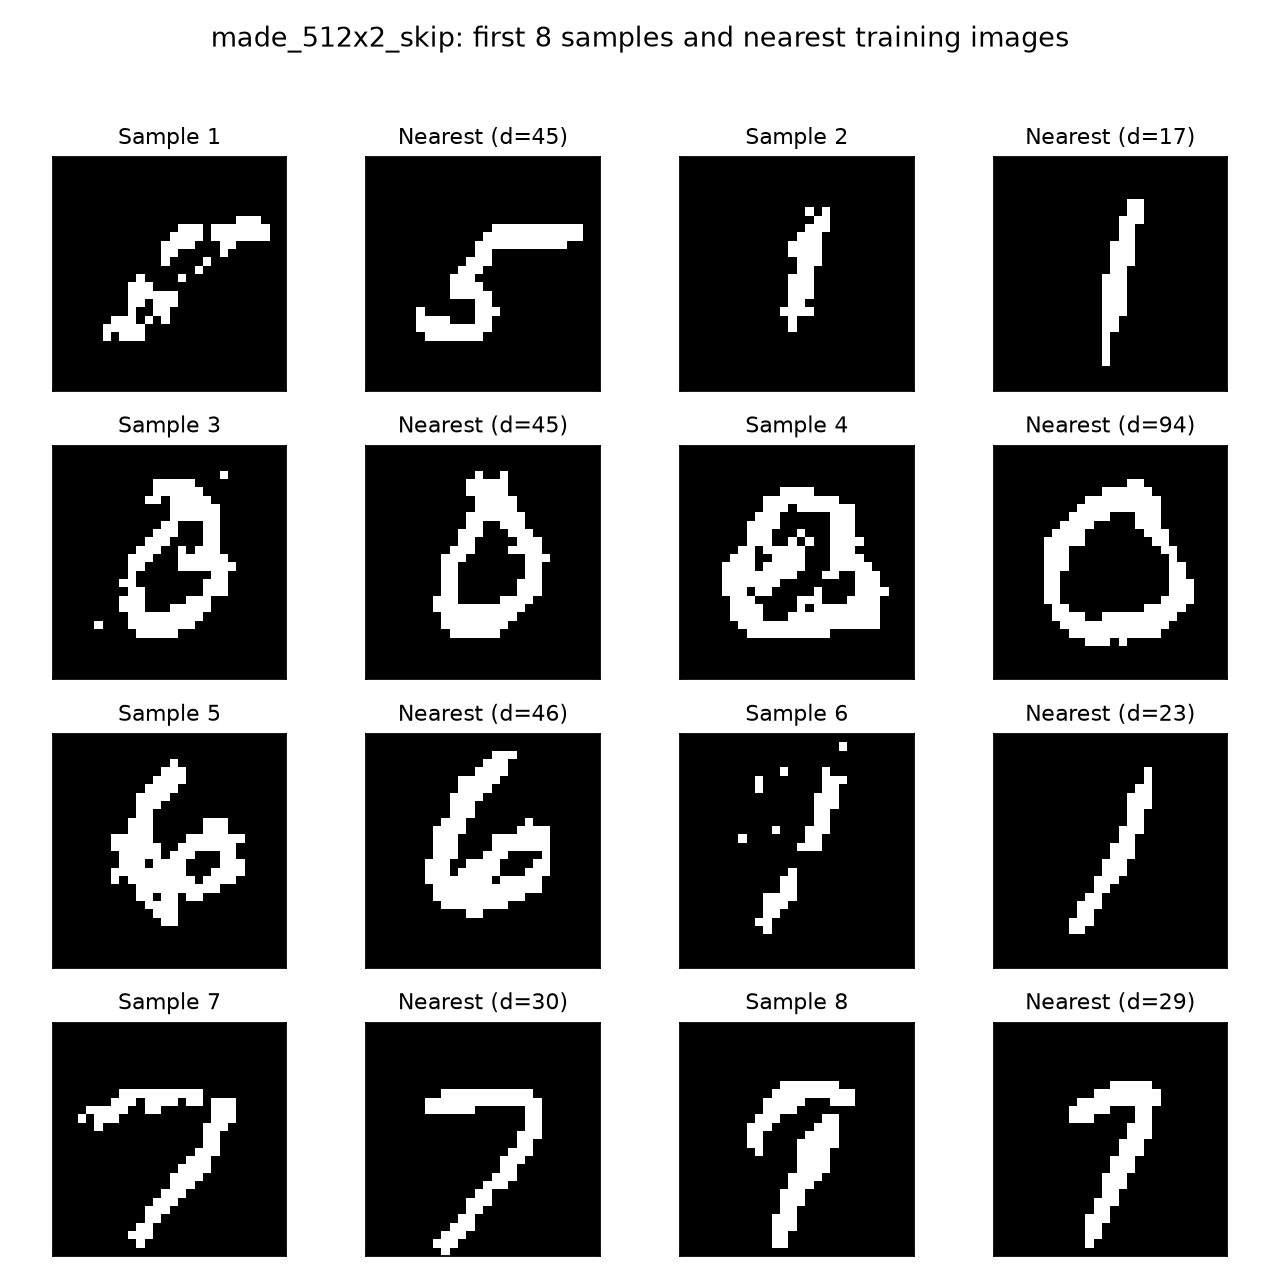

In [6]:
for key in ["task1", "task2"]:
    display(Image(filename=str(RESULTS / selection[key] / "nearest_neighbors.png")))

## Discussion limits, reproducibility and submission checklist

Thresholding simplifies the observation space and loses grayscale detail.
Raster-order factorization does not explicitly encode spatial translation
invariance. A low NLL does not guarantee human-readable or class-balanced samples;
the number of unique binary images is not a measure of digit-class coverage.
An unconditional model is not required to output each digit exactly once.
Visual judgment, held-out likelihood, and runtime should be considered together.

Further work could study alternative pixel orders, more seeds, different
binarization procedures, and convolutional autoregressive models. These are
not claimed as completed experiments. GAN results belong to task 1.3 and are
not inferred from the present autoregressive results.

To reproduce: install `requirements.txt`, run
`python -m unittest test_autoregressive -v`, then
`python run_task12.py --repeat-seeds`, then run all cells in this notebook. Existing compatible complete runs
are reused; use a new `--output` directory to train from scratch.
All preprocessing, hyperparameters, per-epoch losses, weights, per-image test
NLLs, sampled arrays, split indices and timing records are supplied.

Before final submission, complete task 1.3, add the actual accessible shared
code/data URLs, review the conclusions, and export the combined report as
`60815456_60857945_60412495.pdf`. Do not claim this two-task report completes
the whole assignment. No shared URL or submission is fabricated here.

## References

1. Germain, M., Gregor, K., Murray, I., & Larochelle, H. (2015).
   *MADE: Masked Autoencoder for Distribution Estimation*. ICML, PMLR 37, 881–889.
   https://proceedings.mlr.press/v37/germain15.html
2. CS5494 assignment specification, sections 1.1, 1.2, 2.2–2.4 and marking scheme.


## Task 1.3 — GAN (pending)

1.3  implement and train a GAN (you can choose your own encoder and
decoder architecture) for handwritten digit generation on the original MNIST dataset (not the
binarized version). For the training data, you may choose to use either a subset of the training set
or the entire training set, specify your choice (and the size of the subset, if applicable) in your
report. After training, the generator must be able to generate MNIST-like digit images, and you
need to submit some generated images along with a brief report on training stability (e.g., whether
mode collapse occurred).